# stc tv — تحليل سلوك المشاهدين
**الهدف:** فهم سلوك مستخدمي stc tv حسب صنف البرنامج (فيلم / مسلسل) وحسب جودة المشاهدة (SD / HD).

## المرحلة 1: تحميل البيانات وفحصها وتنظيفها
1. تحميل ملف الإكسل
2. التحقق من شكل البيانات (عدد الصفوف والأعمدة)
3. معالجة البيانات والتحقق من القيم الفارغة
4. وصف القيم الرقمية: المتوسط، الانحراف المعياري، القيم العظمى والصغرى

In [1]:
# مكتبة لقراءة ملفات xlsb (غير مثبتة افتراضياً في Colab)
!pip install -q pyxlsb

In [2]:
import pandas as pd
import numpy as np
pd.set_option('display.float_format', '{:,.2f}'.format)

### 1. تحميل البيانات
يُرفع ملف `stc_TV_Data_Set_T1.xlsb` إلى Colab من أيقونة المجلد على اليسار قبل تشغيل الخلية.

In [3]:
FILE = "stc_TV_Data_Set_T1.xlsb"
raw = pd.read_excel(FILE, sheet_name="Final_Dataset", engine="pyxlsb")
df = raw.copy()   # نشتغل على نسخة ونترك الأصل كما هو

### 2. شكل البيانات

In [4]:
rows, cols = df.shape
print(f"عدد الصفوف: {rows:,}")
print(f"عدد الأعمدة: {cols}")
df.head()

عدد الصفوف: 1,048,575
عدد الأعمدة: 13


,Column1,date_,user_id_maped,program_name,duration_seconds,program_class,season,episode,program_desc,program_genre,series_title,hd,original_name
0,1,05/27/2017,26138,100 treets,40,MOVIE,0,0,Drama Movie100 Streets,Drama,0,0,100 treets
1,3,05/21/2017,7946,Moana,17,MOVIE,0,0,Animation MovieMoana (HD),Animation,0,1,Moana
2,4,08/10/2017,7418,The Mermaid Princess,8,MOVIE,0,0,Animation MovieThe Mermaid Princess (HD),Animation,0,1,The Mermaid Princess
3,5,07/26/2017,19307,The Mermaid Princess,76,MOVIE,0,0,Animation MovieThe Mermaid Princess (HD),Animation,0,1,The Mermaid Princess
4,7,07/07/2017,15860,Churchill,87,MOVIE,0,0,Biography MovieChurchill (HD),Biography,0,1,Churchill


In [5]:
# أنواع الأعمدة كما قُرئت من الملف
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 13 columns):
 #   Column            Non-Null Count    Dtype
---  ------            --------------    -----
 0   Column1           1048575 non-null  int64
 1   date_             1048575 non-null  str  
 2   user_id_maped     1048575 non-null  int64
 3   program_name      1048575 non-null  str  
 4   duration_seconds  1048575 non-null  int64
 5   program_class     1048575 non-null  str  
 6   season            1048575 non-null  int64
 7   episode           1048575 non-null  int64
 8   program_desc      1034537 non-null  str  
 9   program_genre     1048575 non-null  str  
 10  series_title      1048575 non-null  int64
 11  hd                1048575 non-null  int64
 12  original_name     1048575 non-null  str  
dtypes: int64(7), str(6)
memory usage: 104.0 MB


### 3. فحص القيم الفارغة **قبل** تحويل الأنواع
مهم نفحص قبل `astype(str)`، لأن التحويل لنص يحوّل القيمة الفارغة إلى النص `"nan"` فتختفي من `isnull()`.

In [6]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({'عدد الفارغ': missing, 'النسبة %': missing_pct})[missing > 0]

,عدد الفارغ,النسبة %
program_desc,14038,1.340


### 4. معالجة البيانات
- حذف عمود الترقيم `Column1`
- تنظيف المسافات من أسماء البرامج
- تحويل التاريخ من رقم إكسل إلى تاريخ
- توحيد أنواع الأعمدة الرقمية والنصية
- معالجة الفراغات في `program_desc`، وتوحيد التصنيف غير المعرّف `NOT_DEFINED_IN_UMS`

In [7]:
df = df.drop(columns=['Column1'])

# أسماء البرامج: إزالة المسافات الزائدة
for c in ['program_name', 'original_name']:
    df[c] = df[c].astype(str).str.strip()

# التاريخ: في ملف xlsb يُخزّن كرقم تسلسلي (أيام منذ 1899-12-30)
if pd.api.types.is_numeric_dtype(df['date_']):
    df['date_'] = pd.to_datetime(df['date_'], unit='D', origin='1899-12-30')
else:
    df['date_'] = pd.to_datetime(df['date_'])

# الأعمدة الرقمية
num_cols = ['duration_seconds', 'season', 'episode', 'series_title', 'hd']
df[num_cols] = df[num_cols].apply(pd.to_numeric)

# الوصف الفارغ: نبنيه من الصنف + اسم البرنامج بدل ما نحذف الصفوف
df['program_desc'] = df['program_desc'].fillna(
    df['program_genre'].str.title() + ' ' + df['program_class'].str.title() + ' ' + df['program_name'])

# التصنيف غير المعرّف
df['program_genre'] = df['program_genre'].replace('NOT_DEFINED_IN_UMS', 'Unknown')

# الأعمدة النصية
text_cols = ['user_id_maped', 'program_name', 'program_class', 'program_desc', 'program_genre', 'original_name']
df[text_cols] = df[text_cols].astype(str)

# أعمدة مساعدة للتحليل
df['duration_min'] = df['duration_seconds'] / 60
df['quality'] = np.where(df['hd'] == 1, 'HD', 'SD')
df['program_class'] = df['program_class'].replace({'SERIES/EPISODES': 'Series', 'MOVIE': 'Movie'})

print("هل بقي أي فراغ؟", df.isnull().any().any())
df.head()

هل بقي أي فراغ؟ False


,date_,user_id_maped,program_name,duration_seconds,program_class,season,episode,program_desc,program_genre,series_title,hd,original_name,duration_min,quality
0,2017-05-27,26138,100 treets,40,Movie,0,0,Drama Movie100 Streets,Drama,0,0,100 treets,0.667,SD
1,2017-05-21,7946,Moana,17,Movie,0,0,Animation MovieMoana (HD),Animation,0,1,Moana,0.283,HD
2,2017-08-10,7418,The Mermaid Princess,8,Movie,0,0,Animation MovieThe Mermaid Princess (HD),Animation,0,1,The Mermaid Princess,0.133,HD
3,2017-07-26,19307,The Mermaid Princess,76,Movie,0,0,Animation MovieThe Mermaid Princess (HD),Animation,0,1,The Mermaid Princess,1.267,HD
4,2017-07-07,15860,Churchill,87,Movie,0,0,Biography MovieChurchill (HD),Biography,0,1,Churchill,1.450,HD


### 5. فحوصات جودة إضافية

In [8]:
print(f"الفترة الزمنية: {df['date_'].min():%Y-%m-%d} إلى {df['date_'].max():%Y-%m-%d}")
print(f"عدد المستخدمين: {df['user_id_maped'].nunique():,}")
print(f"عدد البرامج: {df['program_name'].nunique():,}")
print(f"صفوف مكررة بالكامل: {df.duplicated().sum():,}")
print(f"جلسات أطول من 4 ساعات: {(df['duration_seconds'] > 4*3600).sum():,}")
print()
print(df['program_class'].value_counts())
print(df['quality'].value_counts())

الفترة الزمنية: 2017-03-14 إلى 2018-04-30
عدد المستخدمين: 11,578
عدد البرامج: 8,013
صفوف مكررة بالكامل: 102,074
جلسات أطول من 4 ساعات: 7,553

program_class
Series    560174
Movie     488401
Name: count, dtype: int64
quality
SD    643539
HD    405036
Name: count, dtype: int64


> **ملاحظات:**
> - عدد الصفوف 1,048,575، وهو **الحد الأقصى لصفوف إكسل**. يعني الملف غالباً مقصوص من بيانات أكبر (عمود الترقيم الأصلي يوصل لـ 1,247,852).
> - الصفوف المكررة قد تكون جلسات حقيقية متكررة لنفس المستخدم في نفس اليوم (التاريخ بدون وقت)، فما نحذفها.
> - فيه جلسات طويلة جداً (أعلى قيمة ~17 يوم)، غالباً جهاز تُرك شغّال. بنعالجها في المرحلة 2 قبل حساب المتوسطات.

### 6. وصف القيم الرقمية

In [9]:
# أعمدة رقمية فعلية (user_id و series_title معرّفات، ما لها معنى إحصائي)
stats = df[['duration_seconds', 'duration_min', 'season', 'episode', 'hd']].agg(['mean', 'std', 'min', 'max']).T
stats.columns = ['المتوسط الحسابي', 'الانحراف المعياري', 'القيمة الصغرى', 'القيمة العظمى']
stats

,المتوسط الحسابي,الانحراف المعياري,القيمة الصغرى,القيمة العظمى
duration_seconds,"1,231.0","6,821.1",2.000,"1,461,329.0"
duration_min,20.5,113.7,0.033,"24,355.5"
season,1.342,2.104,0.000,23.0
episode,6.158,12.2,0.000,282.0
hd,0.386,0.487,0.000,1.000


In [10]:
# الوصف الكامل (يشمل الربيعيات والوسيط)
df.describe()

,date_,duration_seconds,season,episode,series_title,hd,duration_min
count,1048575,"1,048,575.0","1,048,575.0","1,048,575.0","1,048,575.0","1,048,575.0","1,048,575.0"
mean,2017-10-04 00:23:20.346183,"1,231.0",1.342,6.158,0.012,0.386,20.5
min,2017-03-14 00:00:00,2.000,0.000,0.000,0.000,0.000,0.033
25%,2017-06-10 00:00:00,52.0,0.000,0.000,0.000,0.000,0.867
50%,2017-10-14 00:00:00,119.0,1.000,1.000,0.000,0.000,1.983
75%,2018-01-21 00:00:00,"1,328.0",1.000,9.000,0.000,1.000,22.1
max,2018-04-30 00:00:00,"1,461,329.0",23.0,282.0,1.000,1.000,"24,355.5"
std,NaN,"6,821.1",2.104,12.2,0.109,0.487,113.7


**قراءة النتائج:**
- **مدة المشاهدة:** المتوسط ~20.5 دقيقة، لكن الوسيط دقيقتين فقط، والانحراف المعياري كبير جداً (~114 دقيقة). هذا يدل على توزيع ملتوي: أغلب الجلسات قصيرة (تصفّح أو مقاطع) وقلة طويلة جداً ترفع المتوسط.
- **HD:** متوسط 0.39، يعني **39%** من الجلسات بجودة عالية و61% بجودة قياسية.
- **الموسم والحلقة:** القيمة 0 تخص الأفلام، وأعلى موسم 23 وأعلى حلقة 282.

## المرحلة 2: تجهيز البيانات للتحليل
### معالجة الجلسات الشاذة
الجلسات الأطول من 4 ساعات غالباً جهاز تُرك شغّال. نستبعدها من حسابات **المدة** فقط، ونبقيها في حساب عدد المستخدمين والمشاهدات.

In [11]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'font.size': 10})
C_MOVIE, C_SERIES = '#B8893B', '#2F4858'
C_HD, C_SD, C_MIX = '#2A7F9E', '#D9822B', '#A7A29A'

MAX_SESSION = 4 * 3600
df['valid_duration'] = df['duration_seconds'] <= MAX_SESSION
print(f"جلسات مستبعدة من حساب المدة: {(~df['valid_duration']).sum():,} ({(~df['valid_duration']).mean():.2%})")

dv = df[df['valid_duration']].copy()
print(f"متوسط الجلسة بعد المعالجة: {dv['duration_min'].mean():.1f} دقيقة (كان {df['duration_min'].mean():.1f})")
print(f"الوسيط: {dv['duration_min'].median():.1f} دقيقة")

جلسات مستبعدة من حساب المدة: 7,553 (0.72%)
متوسط الجلسة بعد المعالجة: 14.8 دقيقة (كان 20.5)
الوسيط: 1.9 دقيقة


In [12]:
# اسم المسلسل بدون رقم الحلقة، لتجميع الحلقات تحت مسلسل واحد
df['title'] = df['program_name']
dv['title'] = dv['program_name']
df['month'] = df['date_'].dt.to_period('M')
dv['month'] = dv['date_'].dt.to_period('M')

## المرحلة 3 (المهمة الأولى): تصنيف وتحليل المشاهدين حسب صنف البرنامج
**الطرق المستخدمة:**
1. **مؤشرات مجمّعة** لكل صنف: عدد المستخدمين، المشاهدات، ساعات المشاهدة، متوسط الجلسة.
2. **تقسيم المستخدمين (Segmentation)** حسب نسبة وقت مشاهدتهم للأفلام: محبو الأفلام، محبو المسلسلات، مشاهدون مختلطون.
3. **تحليل التصنيفات (Genres)** داخل كل صنف.
4. **أعلى البرامج** مشاهدةً في كل صنف.
5. **الاتجاه الزمني** الشهري.

### 3.1 مؤشرات الأفلام مقابل المسلسلات

In [13]:
kpi = df.groupby('program_class').agg(users=('user_id_maped', 'nunique'), sessions=('user_id_maped', 'size'))
kpi = kpi.join(dv.groupby('program_class').agg(watch_hours=('duration_seconds', lambda s: s.sum() / 3600),
                                                avg_session_min=('duration_min', 'mean'),
                                                median_session_min=('duration_min', 'median')))
kpi['sessions_per_user'] = kpi['sessions'] / kpi['users']
kpi['hours_per_user'] = kpi['watch_hours'] / kpi['users']
kpi['share_of_hours'] = kpi['watch_hours'] / kpi['watch_hours'].sum()
kpi

,users,sessions,watch_hours,avg_session_min,median_session_min,sessions_per_user,hours_per_user,share_of_hours
program_class,,,,,,,,
Movie,11355,488401,"74,822.9",9.232,1.283,43.0,6.589,0.291
Series,3901,560174,"181,900.8",19.7,18.2,143.6,46.6,0.709


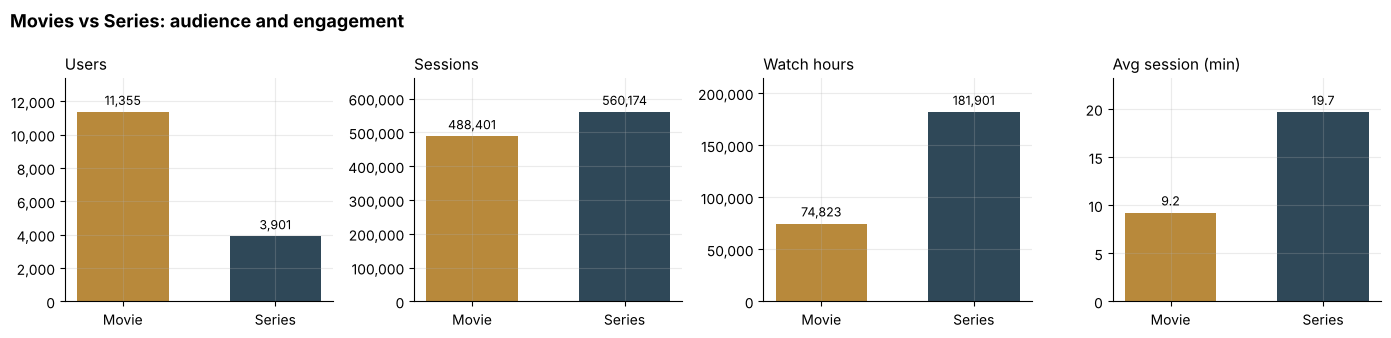

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
metrics = [('users', 'Users'), ('sessions', 'Sessions'), ('watch_hours', 'Watch hours'), ('avg_session_min', 'Avg session (min)')]
for ax, (col, title) in zip(axes, metrics):
    vals = kpi[col]
    bars = ax.bar(vals.index, vals.values, color=[C_MOVIE, C_SERIES], width=.6)
    ax.set_title(title, fontsize=11, loc='left')
    ax.bar_label(bars, labels=[f'{v:,.0f}' if v > 100 else f'{v:,.1f}' for v in vals], padding=3, fontsize=9)
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x:,.0f}'))
    ax.margins(y=.18)
fig.suptitle('Movies vs Series: audience and engagement', x=.01, ha='left', fontsize=13, weight='bold')
plt.tight_layout(); plt.show()

### 3.2 تقسيم المستخدمين حسب تفضيلهم
لكل مستخدم نحسب نسبة وقت مشاهدته للأفلام من إجمالي وقته:
- **محب أفلام:** 70% أو أكثر من وقته أفلام
- **محب مسلسلات:** 30% أو أقل أفلام
- **مختلط:** بينهما

In [15]:
u_time = dv.pivot_table(index='user_id_maped', columns='program_class', values='duration_seconds',
                        aggfunc='sum', fill_value=0)
u_time['movie_share'] = u_time['Movie'] / (u_time['Movie'] + u_time['Series'])
u_time['total_hours'] = (u_time['Movie'] + u_time['Series']) / 3600
u_time['segment'] = pd.cut(u_time['movie_share'], [-0.01, 0.3, 0.7, 1.0],
                           labels=['Series fans', 'Mixed', 'Movie fans'])

seg = u_time.groupby('segment', observed=True).agg(users=('total_hours', 'size'),
                                                   avg_hours_per_user=('total_hours', 'mean'),
                                                   median_hours_per_user=('total_hours', 'median'))
seg['share_of_users'] = seg['users'] / seg['users'].sum()
seg['share_of_total_hours'] = u_time.groupby('segment', observed=True)['total_hours'].sum() / u_time['total_hours'].sum()
seg

,users,avg_hours_per_user,median_hours_per_user,share_of_users,share_of_total_hours
segment,,,,,
Series fans,1623,109.2,51.3,0.140,0.690
Mixed,755,51.8,21.8,0.065,0.152
Movie fans,9193,4.394,0.146,0.794,0.157


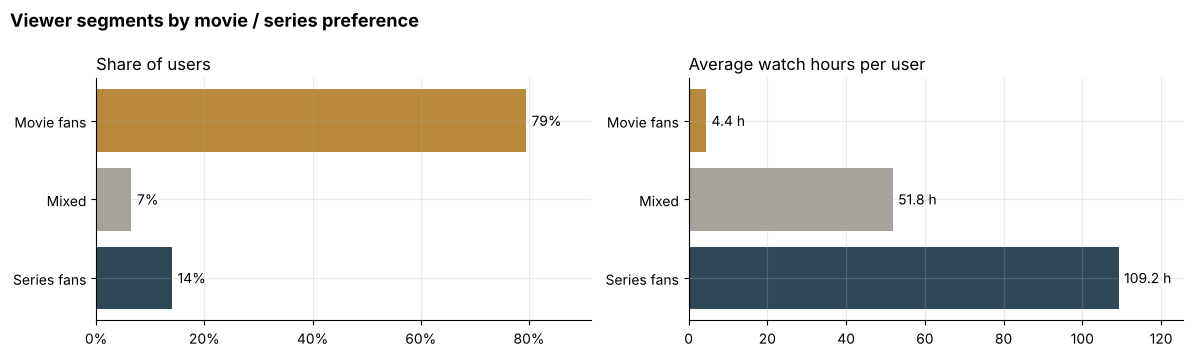

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
order = ['Movie fans', 'Mixed', 'Series fans']; cols = [C_MOVIE, C_MIX, C_SERIES]
s = seg.reindex(order)
b = axes[0].barh(order, s['share_of_users'], color=cols); axes[0].bar_label(b, labels=[f'{v:.0%}' for v in s['share_of_users']], padding=4)
axes[0].set_title('Share of users', loc='left'); axes[0].xaxis.set_major_formatter(mtick.PercentFormatter(1)); axes[0].invert_yaxis()
b = axes[1].barh(order, s['avg_hours_per_user'], color=cols); axes[1].bar_label(b, labels=[f'{v:.1f} h' for v in s['avg_hours_per_user']], padding=4)
axes[1].set_title('Average watch hours per user', loc='left'); axes[1].invert_yaxis()
for a in axes: a.margins(x=.15)
fig.suptitle('Viewer segments by movie / series preference', x=.01, ha='left', fontsize=13, weight='bold')
plt.tight_layout(); plt.show()

### 3.3 التصنيفات الأكثر مشاهدة في كل صنف

In [17]:
genre_hours = dv.groupby(['program_class', 'program_genre'])['duration_seconds'].sum().div(3600).unstack(0).fillna(0)
genre_share = genre_hours / genre_hours.sum()
top_genres = genre_hours.sum(axis=1).sort_values(ascending=False).head(8).index
genre_share.loc[top_genres].round(3)

program_class,Movie,Series
program_genre,,
Animation,0.235,0.331
Action,0.334,0.154
Drama,0.089,0.251
Comedy,0.158,0.113
Horror,0.056,0.078
Thriller,0.065,0.038
Family,0.018,0.024
Documentary,0.009,0.006


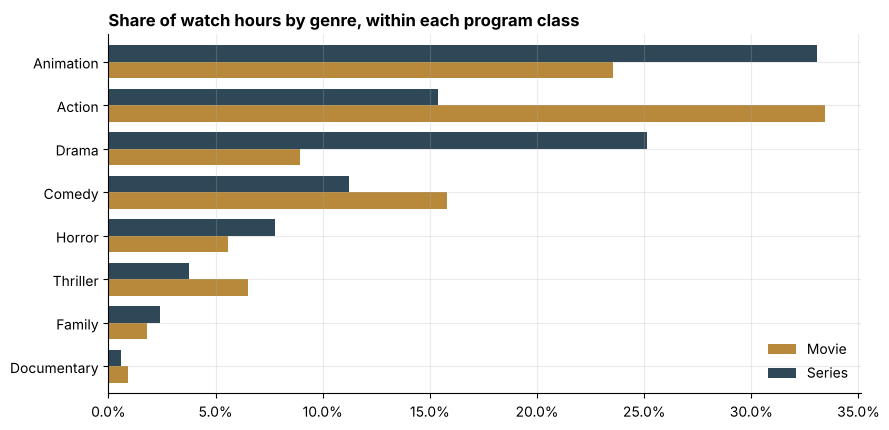

In [18]:
ax = genre_share.loc[top_genres][::-1].plot.barh(figsize=(9, 4.4), color=[C_MOVIE, C_SERIES], width=.75)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_title('Share of watch hours by genre, within each program class', loc='left', fontsize=12, weight='bold')
ax.set_ylabel(''); ax.legend(title='', frameon=False)
plt.tight_layout(); plt.show()

### 3.4 أعلى البرامج مشاهدةً

In [19]:
def top_titles(cls, n=10):
    t = dv[dv['program_class'] == cls].groupby('title').agg(watch_hours=('duration_seconds', lambda s: s.sum() / 3600),
                                                            users=('user_id_maped', 'nunique'),
                                                            sessions=('user_id_maped', 'size'))
    return t.sort_values('watch_hours', ascending=False).head(n)

top_movies, top_series = top_titles('Movie'), top_titles('Series')
display(top_movies)
display(top_series)

,watch_hours,users,sessions
title,,,
The Boss Baby,"2,420.0",3387,23993
The Amazing pider-Man,"1,428.3",1001,2840
Moana,"1,271.1",2172,8047
Trolls,"1,209.7",2610,13767
Bean,"1,192.7",943,3598
The murfs,"1,113.0",864,3105
The Expendables,"1,104.2",840,2073
Hotel Transylvania,777.7,491,1930
Cloudy With a Chance of Meatballs,722.5,681,2060


,watch_hours,users,sessions
title,,,
24 :00 AM - :00 AM,"1,467.6",154,2778
Pingu,"1,461.1",306,17053
24 :00 PM - :00 PM,"1,418.0",86,2622
Caramel (T) Chapter,"1,381.7",155,3158
Jane the Virgin Chapter,"1,040.4",197,2352
In the Night Garden,"1,033.3",160,3303
Teletubbies,951.2,147,3058
Sonic Underground,860.6,346,3254
Oscar's Oasis,838.9,180,7162


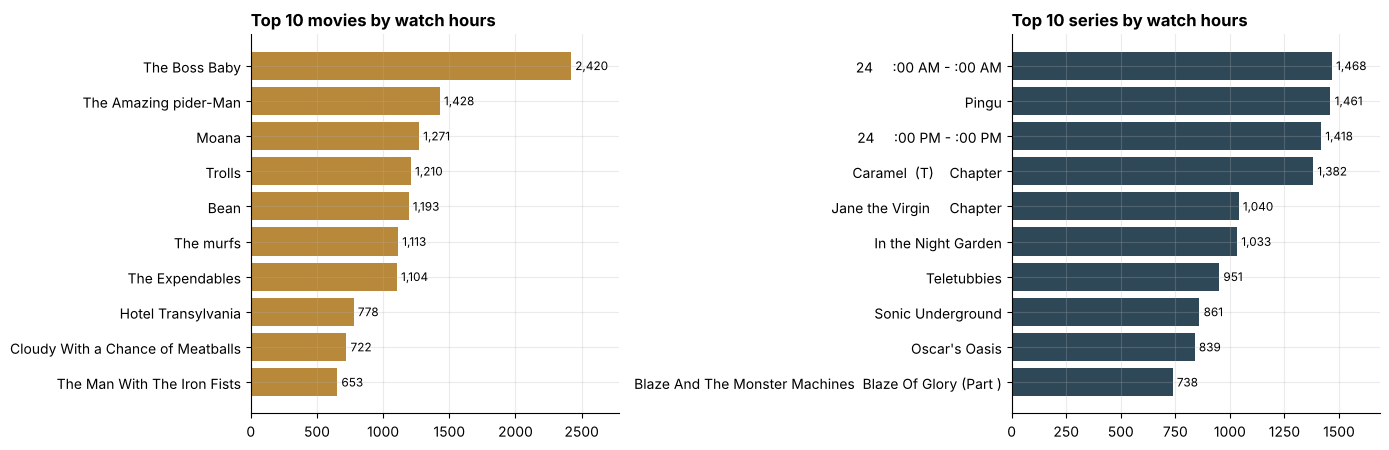

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, t, c, name in [(axes[0], top_movies, C_MOVIE, 'Top 10 movies'), (axes[1], top_series, C_SERIES, 'Top 10 series')]:
    b = ax.barh(t.index[::-1], t['watch_hours'][::-1], color=c)
    ax.bar_label(b, labels=[f'{v:,.0f}' for v in t['watch_hours'][::-1]], padding=3, fontsize=8.5)
    ax.set_title(f'{name} by watch hours', loc='left', fontsize=12, weight='bold'); ax.margins(x=.15)
plt.tight_layout(); plt.show()

### 3.5 الاتجاه الشهري

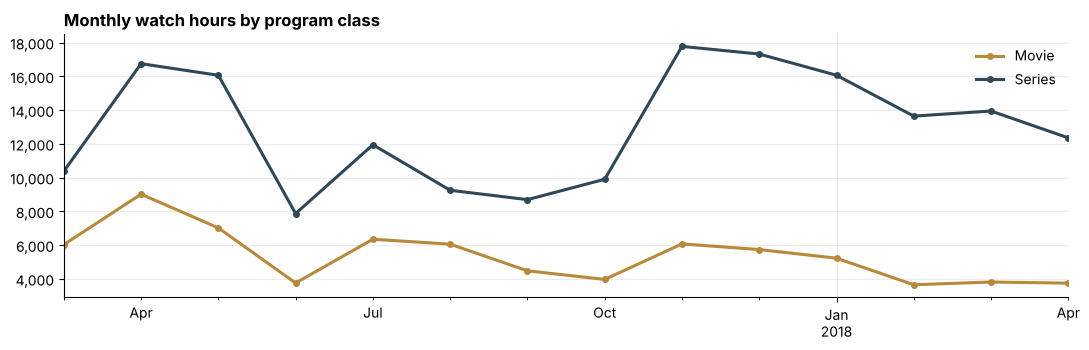

In [21]:
monthly = dv.groupby(['month', 'program_class'])['duration_seconds'].sum().div(3600).unstack()
ax = monthly.plot(figsize=(11, 3.6), color=[C_MOVIE, C_SERIES], lw=2.2, marker='o', ms=4)
ax.set_title('Monthly watch hours by program class', loc='left', fontsize=12, weight='bold')
ax.set_xlabel(''); ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x:,.0f}')); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## المرحلة 4 (المهمة الثانية): أنماط المشاهدة SD مقابل HD
### 4.1 هل الجودة اختيار المستخدم؟
قبل تقسيم المستخدمين، نتحقق: هل نفس البرنامج يُشاهد بالجودتين، أو الجودة مرتبطة بالبرنامج نفسه؟

In [22]:
prog_hd = df.groupby('program_name')['hd'].agg(['min', 'max'])
mixed_programs = (prog_hd['min'] != prog_hd['max']).mean()
print(f"نسبة البرامج اللي تُشاهد بالجودتين: {mixed_programs:.2%}")

quality_by_class = pd.crosstab(df['program_class'], df['quality'], normalize='index')
quality_by_class

نسبة البرامج اللي تُشاهد بالجودتين: 2.93%


quality,HD,SD
program_class,,
Movie,0.679,0.321
Series,0.131,0.869


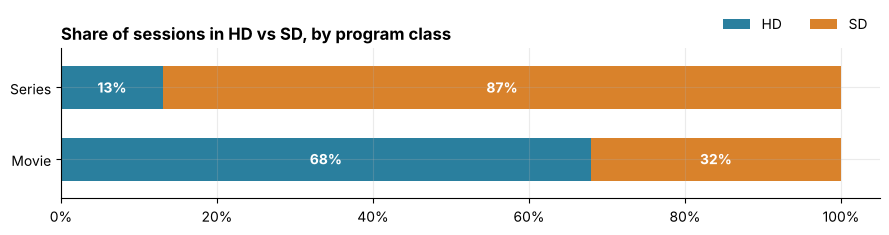

In [23]:
ax = quality_by_class[['HD', 'SD']].plot.barh(stacked=True, figsize=(9, 2.6), color=[C_HD, C_SD], width=.6)
for c in ax.containers: ax.bar_label(c, labels=[f'{v:.0%}' for v in c.datavalues], label_type='center', color='white', fontsize=10, weight='bold')
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_ylabel(''); ax.legend(frameon=False, ncol=2, loc='upper right', bbox_to_anchor=(1, 1.3))
ax.set_title('Share of sessions in HD vs SD, by program class', loc='left', fontsize=12, weight='bold')
plt.tight_layout(); plt.show()

### 4.2 الجودة حسب التصنيف

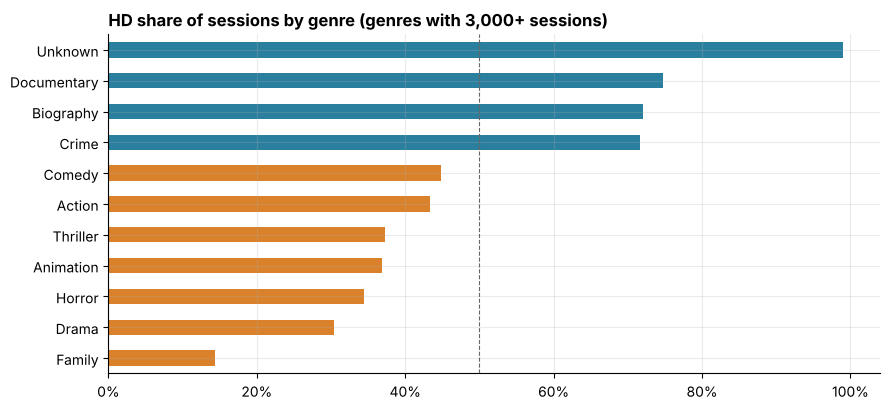

In [24]:
genre_q = df.groupby('program_genre').agg(sessions=('hd', 'size'), hd_share=('hd', 'mean'))
genre_q = genre_q[genre_q['sessions'] > 3000].sort_values('hd_share')
ax = genre_q['hd_share'].plot.barh(figsize=(9, 4.2), color=[C_HD if v >= .5 else C_SD for v in genre_q['hd_share']])
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.axvline(.5, color='#666', lw=.8, ls='--'); ax.set_ylabel('')
ax.set_title('HD share of sessions by genre (genres with 3,000+ sessions)', loc='left', fontsize=12, weight='bold')
plt.tight_layout(); plt.show()

### 4.3 تقسيم المستخدمين حسب الجودة
لكل مستخدم نحسب نسبة جلساته بجودة HD:
- **مشاهد HD:** 80% أو أكثر من جلساته HD
- **مشاهد SD:** 20% أو أقل HD
- **مختلط:** بينهما

In [25]:
uq = df.groupby('user_id_maped').agg(sessions=('hd', 'size'), hd_share=('hd', 'mean'),
                                     movie_sessions_share=('program_class', lambda s: (s == 'Movie').mean()),
                                     top_genre=('program_genre', lambda s: s.value_counts().index[0]))
uq = uq.join(dv.groupby('user_id_maped')['duration_seconds'].sum().div(3600).rename('watch_hours'))
uq['quality_segment'] = pd.cut(uq['hd_share'], [-0.01, 0.2, 0.8, 1.0], labels=['SD viewers', 'Mixed', 'HD viewers'])

qprofile = uq.groupby('quality_segment', observed=True).agg(users=('sessions', 'size'),
                                                            avg_sessions=('sessions', 'mean'),
                                                            median_sessions=('sessions', 'median'),
                                                            avg_watch_hours=('watch_hours', 'mean'),
                                                            movie_share_of_sessions=('movie_sessions_share', 'mean'))
qprofile['share_of_users'] = qprofile['users'] / qprofile['users'].sum()
qprofile

,users,avg_sessions,median_sessions,avg_watch_hours,movie_share_of_sessions,share_of_users
quality_segment,,,,,,
SD viewers,1619,246.2,53.0,78.6,0.450,0.140
Mixed,3826,128.7,38.0,30.9,0.771,0.330
HD viewers,6133,25.7,5.000,1.835,0.974,0.530


In [26]:
top_genre_by_seg = uq.groupby('quality_segment', observed=True)['top_genre'].value_counts(normalize=True).groupby(level=0).head(3)
top_genre_by_seg.rename('share_of_users').to_frame()

share_of_users
quality_segment top_genre                
SD viewers      Animation            0.36
                Action               0.21
                Drama                0.16
Mixed           Animation            0.34
                Action               0.31
                Comedy               0.15
HD viewers      Animation            0.49
                Action               0.16
                Comedy               0.10

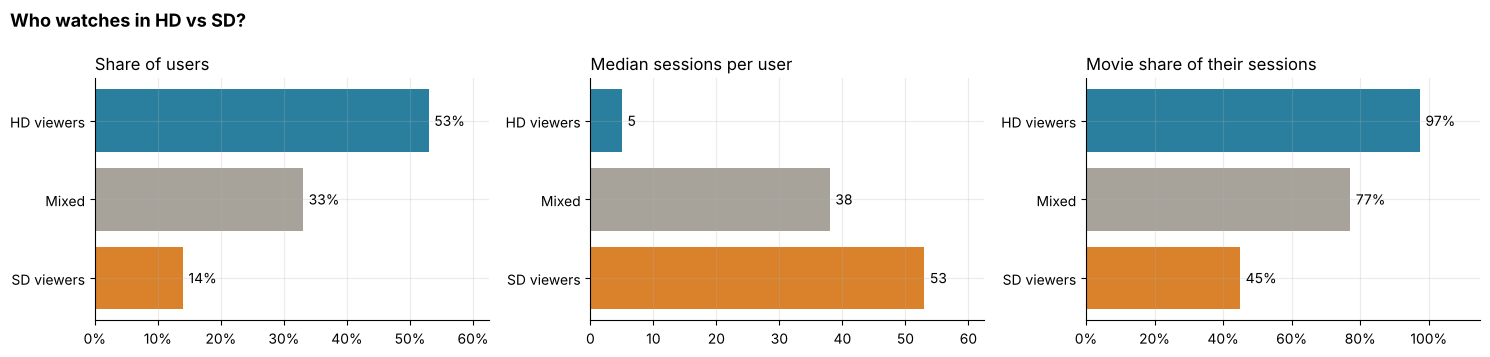

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
order = ['HD viewers', 'Mixed', 'SD viewers']; cols = [C_HD, C_MIX, C_SD]
q = qprofile.reindex(order)
for ax, (col, title, fmt) in zip(axes, [('share_of_users', 'Share of users', '{:.0%}'),
                                       ('median_sessions', 'Median sessions per user', '{:,.0f}'),
                                       ('movie_share_of_sessions', 'Movie share of their sessions', '{:.0%}')]):
    b = ax.barh(order, q[col], color=cols); ax.bar_label(b, labels=[fmt.format(v) for v in q[col]], padding=4)
    ax.set_title(title, loc='left'); ax.invert_yaxis(); ax.margins(x=.18)
    if 'share' in col: ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
fig.suptitle('Who watches in HD vs SD?', x=.01, ha='left', fontsize=13, weight='bold')
plt.tight_layout(); plt.show()

### 4.4 تطوّر نسبة HD عبر الشهور

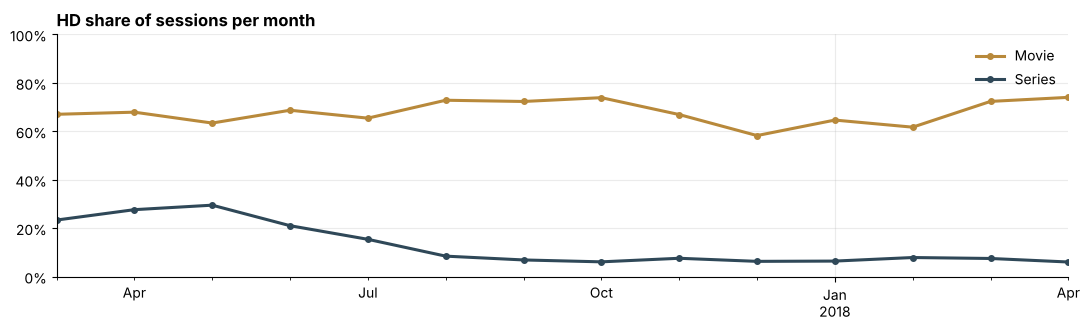

In [28]:
m_q = df.groupby(['month', 'program_class'])['hd'].mean().unstack()
ax = m_q.plot(figsize=(11, 3.4), color=[C_MOVIE, C_SERIES], lw=2.2, marker='o', ms=4)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_ylim(0, 1); ax.set_xlabel(''); ax.legend(frameon=False)
ax.set_title('HD share of sessions per month', loc='left', fontsize=12, weight='bold')
plt.tight_layout(); plt.show()

## المرحلة 5 (المهمة الثالثة): النتائج والتوصيات

### أولاً: الأفلام مقابل المسلسلات
- **الأفلام توصل للكل، والمسلسلات تمسك الجمهور.** 98% من المستخدمين (11,355) شاهدوا أفلام، و34% فقط (3,901) شاهدوا مسلسلات. لكن المسلسلات تمثّل **71% من ساعات المشاهدة**.
- **مشاهدة الأفلام أغلبها تصفّح.** وسيط جلسة الفيلم **1.3 دقيقة** مقابل **18 دقيقة** للمسلسل. يعني أغلب جلسات الأفلام فتح سريع ثم خروج.
- **تقسيم المستخدمين:**
  - **محبو الأفلام:** 79% من المستخدمين، لكن 16% فقط من الساعات، ووسيط مشاهدتهم الإجمالية **9 دقائق** فقط.
  - **محبو المسلسلات:** 14% من المستخدمين، ويصنعون **69% من الساعات** (متوسط 109 ساعة لكل مستخدم).
  - **المختلطون:** 7% من المستخدمين و15% من الساعات.
- **التصنيفات:** الأكشن يتصدّر الأفلام (33% من ساعاتها)، والرسوم المتحركة تتصدّر المسلسلات (33%) يليها الدراما (25%). محتوى الأطفال قوي في الصنفين: The Boss Baby أعلى فيلم، وPingu وTeletubbies من أعلى المسلسلات.

### ثانياً: SD مقابل HD
- **الجودة مرتبطة بالمحتوى، مو باختيار المستخدم.** 97% من البرامج متوفرة بجودة واحدة فقط. 68% من جلسات الأفلام HD، مقابل **13% فقط** من جلسات المسلسلات.
- **مشاهدو HD** (53% من المستخدمين): مشاهدون خفيفون، وسيط **5 جلسات** و**1.8 ساعة** في المتوسط، و97% من جلساتهم أفلام.
- **مشاهدو SD** (14% من المستخدمين): **أكثر الفئات ولاءً**، وسيط 53 جلسة و**79 ساعة** في المتوسط، ونصف جلساتهم مسلسلات.
- **نسبة HD في المسلسلات تراجعت** من 23–30% في ربيع 2017 إلى 6–8% من أغسطس 2017.

### التوصيات
1. **ترقية مكتبة المسلسلات إلى HD:** أكثر المستخدمين ولاءً يشاهدون بجودة قياسية لأن المحتوى نفسه ما يتوفر بجودة عالية.
2. **تحويل متصفحي الأفلام إلى مشاهدين:** 79% من المستخدمين يشاهدون دقائق معدودة. نقترح توصيات مخصصة، ومقاطع دعائية أقصر، ومتابعة "أكمل المشاهدة".
3. **الاستثمار في محتوى الأطفال:** الرسوم المتحركة الأعلى عند كل فئات الجودة والصنفين.
4. **التحقق من جودة البيانات:** أسماء البرامج فيها أحرف وأرقام ناقصة (مثل "The Amazing pider-Man" و"24 :00 AM")، والملف مقصوص عند حد إكسل. التحليل الكامل يحتاج البيانات الأصلية.

### منهجية مختصرة
- استبعاد الجلسات الأطول من 4 ساعات (0.7%) من حسابات المدة فقط.
- التقسيم بعتبات 30% / 70% لتفضيل الصنف، و20% / 80% لتفضيل الجودة.